In [1]:
#code from in class examples
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

Text(0.5, 1.0, 'alcohol vs quality')

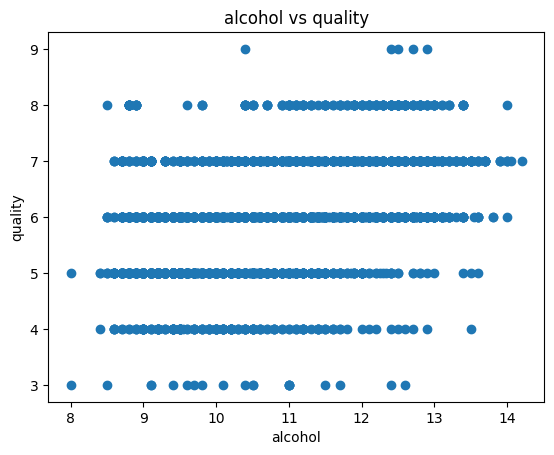

In [2]:
#load in our dataset
wine_df = pd.read_csv('winequality-white.csv', sep=';')
plt.scatter(wine_df['alcohol'], wine_df['quality'])
plt.xlabel("alcohol")
plt.ylabel("quality")
plt.title("alcohol vs quality")
#plt.show()

In [10]:
#manual regression between alcohol and quality

#get our variables
n = len(wine_df.index)
print(n)

sum_x = wine_df["alcohol"].sum()
sum_y = wine_df["quality"].sum()
print(f" Sum of x {sum_x}  sum of y {sum_y}")

x_mean = sum_x / n
y_mean = sum_y / n
print(f" x mean {x_mean}  y mean {y_mean}")

sum_x_times_y = (wine_df["alcohol"] * wine_df["quality"]).sum()
sum_x_squareds = wine_df["alcohol"].pow(2).sum()

print(f" sum_x_times_y {sum_x_times_y}  sum_x_squareds {sum_x_squareds}")

#calculate our numerator and denominator for m 
Sxy = sum_x_times_y - (sum_x * sum_y)/n
Sxx = sum_x_squareds - (sum_x * sum_x)/n
print(f" Sxy {Sxy}  Sxx {Sxx}")


4898
 Sum of x 51498.880000000005  sum of y 28790
 x mean 10.514267047774602  y mean 5.87790935075541
 sum_x_times_y 305030.48333333334  sum_x_squareds 548889.1259111111
 Sxy 2324.735027902527  Sxx 7416.148929812596


In [12]:
#get our line variables 
m = Sxy / Sxx
b = y_mean - m*x_mean

print(f"regression equation: y = {m}x + {b}")

regression equation: y = 0.313469301911831x + 2.5820093991749378


In [13]:
# now lets predict a variable 
row = 5
alcohol_val = wine_df.loc[5, "alcohol"]
quality_val = wine_df.loc[5, "quality"]
predicted_quality = alcohol_val*m + b

print(f"For alcohol value {alcohol_val}, the predicted quality was {predicted_quality}, and the actual value was {quality_val}")

For alcohol value 10.1, the predicted quality was 5.748049348484431, and the actual value was 6


In [17]:
#coefficient of determination 
wine_df["predictions"] = wine_df["alcohol"]*m + b
residual_squares = (wine_df["quality"] - wine_df["predictions"]).pow(2).sum()

total_squares = (wine_df["quality"] - y_mean).pow(2).sum()
r_squared = 1 - (residual_squares/total_squares)
print(f"Coefficient of determination: {r_squared}")

Coefficient of determination: 0.1897253327492563


In [19]:
# now lets run the model with Scikit learn 
linear_regression_model = LinearRegression()

#expects a list of x variables, since is can mutiple resression
#which is why we got fancy with the brackets here
linear_regression_model.fit(wine_df[["alcohol"]], wine_df[["quality"]])
model_m = linear_regression_model.coef_[0][0]
model_b = linear_regression_model.intercept_[0]
print("Scikit learn regresssion model")
print(f"Regression Equation: y = {model_m}x + {model_b}")

Scikit learn regresssion model
Regression Equation: y = 0.3134693019118335x + 2.5820093991749116


In [20]:
#predict tje same value as our own regression 
predicted_model_quality = linear_regression_model.predict([[alcohol_val]])
print(f"For alcohol value {alcohol_val}, the predicted quality was {predicted_model_quality}, and the actual value was {quality_val}")

For alcohol value 10.1, the predicted quality was [[5.74804935]], and the actual value was 6


/Users/dburgess/.venv/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [22]:
#get the coef of determination 
score = linear_regression_model.score(wine_df[["alcohol"]], wine_df[["quality"]])
print(f"coefficient of determination: {score}")

coefficient of determination: 0.18972533274925651


Text(0.5, 1.0, 'alcohol vs quality')

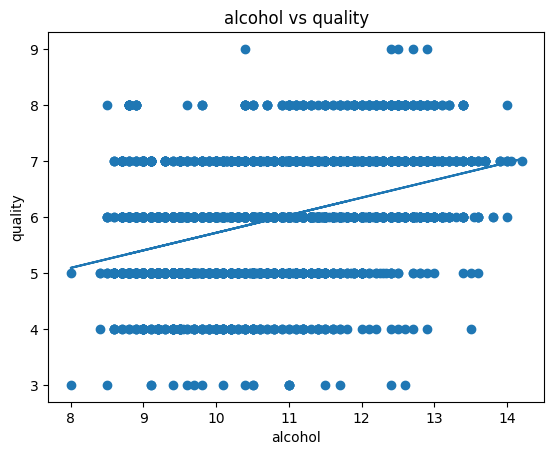

In [23]:
#plot line of best fit
plt.scatter(wine_df["alcohol"], wine_df["quality"])
plt.plot(wine_df["alcohol"], wine_df["predictions"], linestyle="solid")
plt.xlabel("alcohol")
plt.ylabel("quality")
plt.title("alcohol vs quality")

In [24]:
#test and training set 
training_set, testing_set = train_test_split(wine_df, test_size=0.1)

#repeat our linear regression iwth train and test sets
lr_model_2 = LinearRegression()
lr_model_2.fit(training_set[["alcohol"]], training_set[["quality"]])
model_m = lr_model_2.coef_[0][0]
model_b = lr_model_2.intercept_[0]
print("training model")
print(f"Regression Equation: y = {model_m}x + {model_b}")

training model
Regression Equation: y = 0.31442705699783013x + 2.566422906637976


In [25]:
#getting the coef of determination 
score = lr_model_2.score(testing_set[["alcohol"]], testing_set[["quality"]])
print(f"coefficient of determination: {score}")

coefficient of determination: 0.16435452169142473


In [ ]:
#load in our dataset
wine_df = pd.read_csv('winequality-white.csv', sep=';')
regression_list = ["alcohol", "pH", "sulphates"]
outcome_var = wine_df["quality"]
regression_df = wine_df[regression_list]

linear_regression_model = LinearRegression()
linear_regression_model.fit(regression_df, outcome_var)
model_ms = linear_regression_model.coef_
model_b = linear_regression_model.intercept_

#print
